# IT149IU – Lab 6 Assessment: Dictionaries & Sets (Phase A + Phase B)
**Starter notebook.** Edit only `STUDENT_ID` and `STUDENT_NAME` in the first cell, run it, then follow the handout (PDF). Keep the exact function and variable names. Use this **one** notebook for the whole session.

| Phase | Tasks | Points | Submit |
|---|---|---|---|
| **A – compulsory** | 1–4 | 50 | Form A by minute 60, file `IT149IU_Lab6_A_<StudentID>.ipynb` |
| **B – optional** | 5–6 | 40 | Form B by minute 110, file `IT149IU_Lab6_B_<StudentID>.ipynb` |
| Report | – | 10 | Form C within 24 h |

**Difficulty:** <font color="#2E7D32">⭐ Warm-up (T1, T2)</font> → <font color="#0070C0">⭐⭐ Basic (T3)</font> → <font color="#B45309">⭐⭐⭐ Intermediate (T4, T5)</font> → <font color="#B91C1C">⭐⭐⭐⭐ Challenge (T6)</font>

Late work (within 24 h, Form C) counts 50%, and only if it is better than your on-time work.

**Student:** Nguyễn Viết Huy · **ID:** ITDSIU24021 · **Class/Group:** IT149IU – Group 01


In [1]:
# ===== SETUP CELL - run this first. Edit ONLY the two lines below. =====
STUDENT_ID   = "ITDSIU24021"      # <- replace with YOUR student ID
STUDENT_NAME = "Nguyễn Viết Huy"   # <- replace with YOUR full name

import random, copy
_seed = int("".join(c for c in STUDENT_ID if c.isdigit())[-6:] or "0")
_rng = random.Random(_seed)

# --- Task 1: club membership ---
_pool = ["An", "Binh", "Chi", "Dung", "Em", "Giang", "Hoa",
         "Khang", "Lan", "Minh", "Nam", "Oanh", "Phuc", "Quyen"]
while True:
    chess, robotics, music = (set(_rng.sample(_pool, 7)) for _ in range(3))
    _all3 = chess & robotics & music
    _only = chess - robotics - music
    if _all3 and _only and (chess & robotics) - music:
        break

# --- Task 2: raw e-mail list ---
_users = ["an.nguyen", "binh.tran", "chi.pham", "dung.le", "em.vo", "giang.ho"]
_doms = ["hcmiu.edu.vn", "gmail.com", "outlook.com"]
_base = [f"{u}@{d}" for u in _users for d in _doms]
emails = []
for _ in range(16):
    _e = _rng.choice(_base)
    emails.append(_rng.choice([_e, _e.upper(), _e.title(), "  " + _e + " "]))

# --- Task 3: text ---
_sent = [
    "The quick brown fox jumps over the lazy dog.",
    "A dictionary maps keys to values; a set stores unique items!",
    "Python makes data processing simple, readable and fun.",
    "The fox and the dog became friends in the end.",
    "Every key in a dictionary must be unique, but values may repeat.",
    "Sets remove duplicates; dictionaries count things.",
    "Practice makes the code better: read, write, test, repeat.",
    "Data science starts with clean data and clear questions.",
    "The best way to learn Python is to write Python every day.",
    "Unique keys, simple values: that is the dictionary idea.",
]
text = " ".join(_rng.sample(_sent, 4))

# --- Task 5: staff records (nested dictionary) ---
_names = ["Alice Nguyen", "Binh Tran", "Cindy Pham", "David Le", "Emily Vo",
          "Frank Dang", "Grace Ho", "Henry Bui", "Irene Do", "Jack Ly",
          "Kelly Mai", "Leo Truong", "Mona Cao", "Nick Dinh"]
_br = ["HCM", "HN", "DN", "CT"] * 3
_rng.shuffle(_br)
_sal = _rng.sample(range(900, 2500, 50), 12)
_who = _rng.sample(_names, 12)
staff = {f"E{1001 + i}": {"name": _who[i], "branch": _br[i], "salary": _sal[i]}
         for i in range(12)}

# --- Task 6: words and documents ---
_groups = [("listen", "silent", "enlist", "tinsel"), ("google", "gogole"),
           ("cat", "act", "tac"), ("evil", "vile", "live", "veil"),
           ("stone", "notes", "onset"), ("race", "care", "acre"),
           ("dusty", "study")]
words = [w for g in _rng.sample(_groups, 4) for w in g]
words += ["python", "lab", "dog", "loop"]
_rng.shuffle(words)
_docs = [
    "python is simple and fun",
    "a set stores unique items",
    "a dictionary maps keys to values",
    "python sets and dictionaries are fun",
    "unique keys in a dictionary",
    "data science uses python and sets",
    "simple data simple code",
    "values may repeat but keys are unique",
]
docs = {f"D{i + 1}": t for i, t in enumerate(_rng.sample(_docs, 6))}

print("Setup OK for", STUDENT_ID, "-", STUDENT_NAME)
print("Variables: chess, robotics, music, emails, text, staff, words, docs")


Setup OK for ITDSIU24021 - Nguyễn Viết Huy
Variables: chess, robotics, music, emails, text, staff, words, docs


# PHASE A – <font color="#2E7D32">Core (compulsory) · Tasks 1–4 · ⭐ → ⭐⭐⭐ · 50 pts · submit Form A by minute 60</font>

## Task 1 – <font color="#2E7D32">Set operations on club membership</font>

<font color="#2E7D32">**Level 1 ⭐ (Warm-up)** · ⏱ ≈ 10 min · **10 pts**</font>

> <font color="#2E7D32">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

In [2]:
# Task 1: set operations on club membership
in_all = chess & robotics & music
only_chess = chess - robotics - music
in_exactly_two = ((chess & robotics) | (chess & music) | (robotics & music)) - in_all
in_at_least_one = chess | robotics | music
robotics_xor_music = robotics ^ music

print("Chess members:", sorted(chess))
print("Robotics members:", sorted(robotics))
print("Music members:", sorted(music))
print("In all three clubs:", sorted(in_all))
print("Only chess:", sorted(only_chess))
print("In exactly two clubs:", sorted(in_exactly_two))
print("In at least one club:", sorted(in_at_least_one))
print("Robotics XOR music:", sorted(robotics_xor_music))

# Basic consistency checks
assert in_all <= chess and in_all <= robotics and in_all <= music
assert only_chess.isdisjoint(robotics | music)
assert in_exactly_two.isdisjoint(in_all)
assert in_at_least_one == chess | robotics | music
assert robotics_xor_music == (robotics | music) - (robotics & music)
print("Task 1 checks: PASS")


Chess members: ['Chi', 'Em', 'Giang', 'Hoa', 'Nam', 'Oanh', 'Phuc']
Robotics members: ['Chi', 'Em', 'Lan', 'Minh', 'Nam', 'Phuc', 'Quyen']
Music members: ['Binh', 'Hoa', 'Khang', 'Lan', 'Nam', 'Phuc', 'Quyen']
In all three clubs: ['Nam', 'Phuc']
Only chess: ['Giang', 'Oanh']
In exactly two clubs: ['Chi', 'Em', 'Hoa', 'Lan', 'Quyen']
In at least one club: ['Binh', 'Chi', 'Em', 'Giang', 'Hoa', 'Khang', 'Lan', 'Minh', 'Nam', 'Oanh', 'Phuc', 'Quyen']
Robotics XOR music: ['Binh', 'Chi', 'Em', 'Hoa', 'Khang', 'Minh']
Task 1 checks: PASS


## Task 2 – <font color="#2E7D32">Cleaning an e-mail list</font>

<font color="#2E7D32">**Level 1 ⭐ (Warm-up)** · ⏱ ≈ 12 min · **10 pts**</font>

> <font color="#2E7D32">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

In [3]:
# Task 2: cleaning an e-mail list

def _normalise_email(email):
    """Return a normalized address, or None when the input is malformed."""
    if not isinstance(email, str):
        return None
    value = email.strip().lower()
    if value.count("@") != 1:
        return None
    local, domain = value.split("@")
    if not local or not domain or "." not in domain:
        return None
    if any(ch.isspace() for ch in value):
        return None
    return value


def unique_emails(emails):
    """Normalize addresses and remove duplicates, preserving first-seen order."""
    result = []
    seen = set()
    for email in emails:
        normalized = _normalise_email(email)
        if normalized is not None and normalized not in seen:
            result.append(normalized)
            seen.add(normalized)
    return result


def domain_counts(emails):
    """Count valid normalized addresses by domain (duplicate entries count)."""
    counts = {}
    for email in emails:
        normalized = _normalise_email(email)
        if normalized is not None:
            domain = normalized.rsplit("@", 1)[1]
            counts[domain] = counts.get(domain, 0) + 1
    return dict(sorted(counts.items()))


cleaned_emails = unique_emails(emails)
counts_by_domain = domain_counts(emails)
print("Raw e-mail entries:", len(emails))
print("Unique normalized e-mails:", len(cleaned_emails))
for address in cleaned_emails:
    print(" ", address)
print("Domain counts (all valid raw entries):", counts_by_domain)

assert len(cleaned_emails) == len(set(cleaned_emails))
assert all(address == address.strip().lower() for address in cleaned_emails)
assert sum(counts_by_domain.values()) <= len(emails)
assert unique_emails([" A@EXAMPLE.COM ", "a@example.com", "bad-address"]) == ["a@example.com"]
assert domain_counts([" A@EXAMPLE.COM ", "a@example.com", "b@gmail.com"]) == {
    "example.com": 2, "gmail.com": 1
}
print("Task 2 checks: PASS")


Raw e-mail entries: 16
Unique normalized e-mails: 12
  dung.le@outlook.com
  giang.ho@gmail.com
  em.vo@outlook.com
  binh.tran@gmail.com
  chi.pham@gmail.com
  giang.ho@hcmiu.edu.vn
  chi.pham@hcmiu.edu.vn
  binh.tran@hcmiu.edu.vn
  an.nguyen@outlook.com
  giang.ho@outlook.com
  dung.le@gmail.com
  an.nguyen@gmail.com
Domain counts (all valid raw entries): {'gmail.com': 7, 'hcmiu.edu.vn': 4, 'outlook.com': 5}
Task 2 checks: PASS


## Task 3 – <font color="#0070C0">Word frequency</font>

<font color="#0070C0">**Level 2 ⭐⭐ (Basic)** · ⏱ ≈ 15 min · **15 pts**</font>

> <font color="#0070C0">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

In [4]:
# Task 3: word frequency
import re


def word_freq(text):
    """Return a dictionary of lowercase word frequencies; punctuation is ignored."""
    words_found = re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", str(text).lower())
    frequencies = {}
    for word in words_found:
        frequencies[word] = frequencies.get(word, 0) + 1
    return frequencies


def top_n(freq, n):
    """Return up to n (word, count) pairs, count descending and word ascending."""
    if n <= 0:
        return []
    return sorted(freq.items(), key=lambda item: (-item[1], item[0]))[:n]


def longest_word(freq):
    """Return the longest word key; alphabetical order breaks length ties."""
    if not freq:
        return None
    return min(freq, key=lambda word: (-len(word), word))


freq = word_freq(text)
total_words = sum(freq.values())
print("Total words:", total_words)
print("Distinct words:", len(freq))
print("Top 10:", top_n(freq, 10))
print("Longest word:", longest_word(freq))
assert sum(freq.values()) == len(re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", text.lower()))
assert top_n({"pear": 2, "apple": 2, "plum": 1}, 2) == [("apple", 2), ("pear", 2)]
assert longest_word({"cat": 3, "zebra": 1, "apple": 2}) == "apple"
assert longest_word({}) is None
print("Task 3 checks: PASS")


Total words: 39
Distinct words: 29
Top 10: [('the', 4), ('a', 2), ('and', 2), ('data', 2), ('dictionary', 2), ('keys', 2), ('unique', 2), ('values', 2), ('became', 1), ('clean', 1)]
Longest word: dictionary
Task 3 checks: PASS


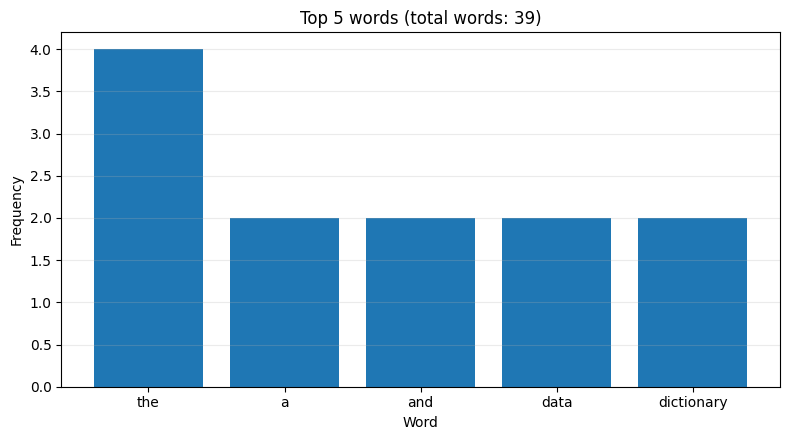

In [5]:
# Bar chart of the top 5 words (title includes the total number of words)
import matplotlib.pyplot as plt

_chart_items = top_n(freq, 5)
_chart_words = [item[0] for item in _chart_items]
_chart_counts = [item[1] for item in _chart_items]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(_chart_words, _chart_counts)
ax.set_xlabel("Word")
ax.set_ylabel("Frequency")
ax.set_title(f"Top 5 words (total words: {total_words})")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("outputs/task3_top5_words.png", dpi=160)
plt.show()


## Task 4 – <font color="#B45309">Find the bugs in AI-generated code</font>

<font color="#B45309">**Level 3 ⭐⭐⭐ (Intermediate)** · ⏱ ≈ 18 min · **15 pts**</font>

> <font color="#B45309">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

Fix the three functions below (same names). Then explain **each of the 4 bugs** in the Markdown cell underneath.

In [6]:
# Task 4: corrected functions for the four identified bugs

def merge_inventories(a, b):
    """Merge two {item: qty} dictionaries, return a new dict, and do not mutate inputs."""
    result = a.copy()
    for item, quantity in b.items():
        result[item] = result.get(item, 0) + quantity
    return result


def unique_tags(records):
    """Return the set of all distinct tags in records."""
    tags = set()
    for record in records:
        for tag in record.get("tags", []):
            tags.add(tag)
    return tags


def remove_empty(d):
    """Remove in place every key whose value equals zero, then return d."""
    for key in list(d):
        if d[key] == 0:
            del d[key]
    return d


_inventory_a = {"pen": 10, "book": 4}
_inventory_b = {"pen": 3, "pencil": 8}
_merged = merge_inventories(_inventory_a, _inventory_b)
_records = [{"tags": ["python", "beginner"]}, {"tags": ["python", "data"]}]
_tag_set = unique_tags(_records)
_stock = {"pen": 10, "book": 0, "eraser": 0, "pencil": 5}
_removed = remove_empty(_stock)
print("Merged inventory:", _merged)
print("Input A unchanged:", _inventory_a)
print("Input B unchanged:", _inventory_b)
print("Unique tags:", sorted(_tag_set))
print("After removing zero quantities:", _removed)
assert _merged == {"pen": 13, "book": 4, "pencil": 8}
assert _inventory_a == {"pen": 10, "book": 4}
assert _inventory_b == {"pen": 3, "pencil": 8}
assert _tag_set == {"python", "beginner", "data"}
assert _removed == {"pen": 10, "pencil": 5}
print("Task 4 checks: PASS")


Merged inventory: {'pen': 13, 'book': 4, 'pencil': 8}
Input A unchanged: {'pen': 10, 'book': 4}
Input B unchanged: {'pen': 3, 'pencil': 8}
Unique tags: ['beginner', 'data', 'python']
After removing zero quantities: {'pen': 10, 'pencil': 5}
Task 4 checks: PASS


**Bug explanations (line / what goes wrong + failing example / fix):**

1. **`merge_inventories`: aliasing and unintended mutation.** `result = a` does not create a new dictionary; it makes `result` refer to `a`. Updating an existing item also changes the caller's dictionary. For example, merging `{"pen": 2}` with `{"pen": 3}` changes the original first dictionary to `{"pen": 5}`. **Fix:** start with `a.copy()` and then add the values from `b`.

2. **`unique_tags`: wrong container type.** `tags = {}` creates a dictionary, but the task requires a set of distinct tags. **Fix:** use `tags = set()`.

3. **`unique_tags`: `set.add()` returns `None`.** The statement `tags = tags.add(t)` overwrites `tags` with `None`; the next iteration then fails. **Fix:** call `tags.add(t)` on its own line.

4. **`remove_empty`: mutating a dictionary during iteration.** Deleting keys from `d` while iterating directly over `d` can raise `RuntimeError: dictionary changed size during iteration`. **Fix:** iterate over a snapshot such as `list(d)` and delete from the original dictionary.


---
## ✅ End of Phase A – submit now
*Runtime → Restart session and run all* → check there is no error → *File → Download → .ipynb* → rename to `IT149IU_Lab6_A_<StudentID>.ipynb` → upload to **Form A**.

Then continue below in this same notebook.

---

# PHASE B – <font color="#B91C1C">Advanced (optional) · Tasks 5–6 · ⭐⭐⭐ → ⭐⭐⭐⭐ · 40 pts · submit Form B by minute 110</font>

## Task 5 – <font color="#B45309">Staff records (nested dictionary)</font>

<font color="#B45309">**Level 3 ⭐⭐⭐ (Intermediate)** · ⏱ ≈ 22 min · **20 pts**</font>

> <font color="#B45309">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

In [7]:
# Task 5: staff records (nested dictionary)

def by_branch(staff):
    """Return {branch: [(employee_id, record), ...]}, sorted by employee ID."""
    grouped = {}
    for employee_id, record in staff.items():
        grouped.setdefault(record["branch"], []).append((employee_id, record.copy()))
    for branch in grouped:
        grouped[branch].sort(key=lambda pair: pair[0])
    return dict(sorted(grouped.items()))


def avg_salary_by_branch(staff):
    """Return average salary for each branch."""
    totals = {}
    counts = {}
    for record in staff.values():
        branch = record["branch"]
        totals[branch] = totals.get(branch, 0) + record["salary"]
        counts[branch] = counts.get(branch, 0) + 1
    return {branch: totals[branch] / counts[branch] for branch in sorted(totals)}


def highest_paid(staff):
    """Return (employee_id, record copy) for the highest-paid employee, or None."""
    if not staff:
        return None
    employee_id = max(staff, key=lambda key: (staff[key]["salary"], key))
    return employee_id, staff[employee_id].copy()


def raise_salary(staff, branch, pct):
    """Raise salaries in branch in place; pct can be 0.05 or 5 for a 5% increase.
    Return the number of changed staff records.
    """
    rate = pct / 100 if abs(pct) > 1 else pct
    if rate < -1:
        raise ValueError("A salary decrease cannot exceed 100%.")
    changed = 0
    for record in staff.values():
        if record["branch"] == branch:
            record["salary"] = round(record["salary"] * (1 + rate), 2)
            changed += 1
    return changed


def print_staff_table(staff):
    """Print staff in a readable table sorted by employee ID."""
    print(f"{'ID':<8} {'Name':<18} {'Branch':<8} {'Salary':>10}")
    print("-" * 48)
    for employee_id in sorted(staff):
        record = staff[employee_id]
        print(f"{employee_id:<8} {record['name']:<18} {record['branch']:<8} {record['salary']:>10.2f}")


print("Staff table:")
print_staff_table(staff)
print("\nStaff count by branch:", {branch: len(rows) for branch, rows in by_branch(staff).items()})
print("Average salary by branch:", {k: round(v, 2) for k, v in avg_salary_by_branch(staff).items()})
print("Highest paid:", highest_paid(staff))
_test_staff = copy.deepcopy(staff)
_target_branch = sorted({rec["branch"] for rec in _test_staff.values()})[0]
_changed = raise_salary(_test_staff, _target_branch, 5)
print(f"Raised salary by 5% in {_target_branch}: {_changed} records updated")
assert sum(len(rows) for rows in by_branch(staff).values()) == len(staff)
assert set(avg_salary_by_branch(staff)) == {r["branch"] for r in staff.values()}
assert highest_paid(staff) is not None
assert all(staff[k]["salary"] == _test_staff[k]["salary"] for k in staff if staff[k]["branch"] != _target_branch)
assert any(staff[k]["salary"] != _test_staff[k]["salary"] for k in staff if staff[k]["branch"] == _target_branch)
print("Task 5 checks: PASS")


Staff table:
ID       Name               Branch       Salary
------------------------------------------------
E1001    David Le           DN          1850.00
E1002    Cindy Pham         HN          2200.00
E1003    Binh Tran          DN          1050.00
E1004    Irene Do           HN          1250.00
E1005    Frank Dang         CT          1000.00
E1006    Mona Cao           CT          2050.00
E1007    Kelly Mai          HCM         1500.00
E1008    Henry Bui          DN          1400.00
E1009    Grace Ho           CT          1950.00
E1010    Nick Dinh          HN          1550.00
E1011    Leo Truong         HCM         1600.00
E1012    Jack Ly            HCM         1300.00

Staff count by branch: {'CT': 3, 'DN': 3, 'HCM': 3, 'HN': 3}
Average salary by branch: {'CT': 1666.67, 'DN': 1433.33, 'HCM': 1466.67, 'HN': 1666.67}
Highest paid: ('E1002', {'name': 'Cindy Pham', 'branch': 'HN', 'salary': 2200})
Raised salary by 5% in CT: 3 records updated
Task 5 checks: PASS


## Task 6 – <font color="#B91C1C">Anagrams and a mini search engine</font>

<font color="#B91C1C">**Level 4 ⭐⭐⭐⭐ (Advanced / Challenge)** · ⏱ ≈ 25 min · **20 pts**</font>

> <font color="#B91C1C">📝 **Plan first (2 min):** ① Input? ② Output? ③ a tiny example by hand ④ steps in plain words → then code ⑤ test with the examples from the PDF.</font>

In [8]:
# Task 6: anagrams and a mini search engine
import re


def _word_key(word):
    """Normalize a word for anagram comparison."""
    return "".join(sorted(re.sub(r"[^a-z0-9]", "", str(word).lower())))


def anagram_groups(words):
    """Return groups of words sharing an anagram key; omit singleton groups."""
    groups = {}
    for word in words:
        key = _word_key(word)
        if key:
            groups.setdefault(key, []).append(word)
    return [group for group in groups.values() if len(group) > 1]


def inverted_index(docs):
    """Build {lowercase_word: set(document_ids)} from {document_id: text}."""
    index = {}
    for document_id, content in docs.items():
        for word in set(re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", str(content).lower())):
            index.setdefault(word, set()).add(document_id)
    return index


def search_and(index, w1, w2):
    """Return document IDs containing both terms."""
    return index.get(str(w1).lower(), set()) & index.get(str(w2).lower(), set())


def search_or(index, w1, w2):
    """Return document IDs containing either or both terms."""
    return index.get(str(w1).lower(), set()) | index.get(str(w2).lower(), set())


print("Anagram groups:", anagram_groups(words))
index = inverted_index(docs)
print("Indexed terms:", len(index))
print("Search AND ('python', 'sets'):", sorted(search_and(index, "python", "sets")))
print("Search OR ('python', 'sets'):", sorted(search_or(index, "python", "sets")))
assert all(len(group) >= 2 for group in anagram_groups(words))
assert search_and({"python": {"D1", "D2"}, "sets": {"D2", "D3"}}, "python", "sets") == {"D2"}
assert search_or({"python": {"D1", "D2"}, "sets": {"D2", "D3"}}, "python", "sets") == {"D1", "D2", "D3"}
assert inverted_index({"D1": "Python python sets!"}) == {"python": {"D1"}, "sets": {"D1"}}
print("Task 6 checks: PASS")


Anagram groups: [['onset', 'notes', 'stone'], ['google', 'gogole'], ['enlist', 'tinsel', 'silent', 'listen'], ['dusty', 'study']]
Indexed terms: 22
Search AND ('python', 'sets'): ['D1', 'D6']
Search OR ('python', 'sets'): ['D1', 'D2', 'D6']
Task 6 checks: PASS


---
## ✅ End of Phase B – submit
Restart and run all → download the **whole** notebook as `IT149IU_Lab6_B_<StudentID>.ipynb` → upload to **Form B** by minute 110.

Within 24 h: upload your report (and, optionally, an improved notebook `IT149IU_Lab6_C_<StudentID>.ipynb`) to **Form C**.